<a href="https://colab.research.google.com/github/RomanPhys/llm-feature-search/blob/main/llm_feature_search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LLM-предложения признаков против случайного поиска при равном бюджете

**Вопрос.** Если LLM предлагает признаки для градиентного бустинга и качество растёт, откуда этот рост?
Возможных источников три.
1. **Грамматика признаков**, то есть агрегат по окну и фильтру. Это заслуга того, кто её придумал, а не LLM.
2. **Знание о смысле категорий.** LLM группирует коды MCC по смыслу, например в продукты, наличные и переводы.
3. **Сам выбор кандидатов LLM** внутри грамматики.

Есть и ложный источник, **больше вычислений**. Если один метод перебрал больше кандидатов
или отбирал их мягче, он почти всегда найдёт прирост на валидации, которого на самом деле нет.

**Что я сравниваю.** У всех источников одинаковые данные, разбиение, базовый набор F0,
число кандидатов, модель и правило отбора. Меняется только то, кто выбирает кандидатов.

| источник | что знает |
|---|---|
| random_raw | грамматику, частые коды MCC по отдельности и значения других категориальных полей |
| random_groups | то же, но вместо отдельных кодов MCC смысловые группы, придуманные LLM |
| llm | грамматику, группы и сам выбирает кандидатов |

Разница random_groups и random_raw показывает вклад групп, разница llm и random_groups показывает вклад выбора кандидатов.
Каждый источник я проверяю с двумя правилами отбора. Правило naive принимает признак, если прирост на валидации больше нуля, как в CAAFE.
Правило strict принимает его, только если прирост значим по парному бутстрэпу с поправкой Холма. Разрыв между приростом на валидации и на тесте показывает, насколько отбор переобучается.

In [4]:
!git clone https://github.com/RomanPhys/llm-feature-search
%cd llm-feature-search
!pip install -q lightgbm huggingface_hub
import os, sys
sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)

Cloning into 'llm-feature-search'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 18 (delta 0), reused 18 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 25.75 KiB | 1.03 MiB/s, done.
/content/llm-feature-search


In [5]:
DATA = "rosbank"          # "rosbank" или "synthetic" (синтетика только для проверки кода)
F0_KIND = "strong"       # "basic": 15 общих агрегатов; "strong": плюс доли по типам операций и частым MCC
RANDOM_SEEDS = 10         # сколько независимых случайных пулов каждого вида
N_BOOT = 500              # бутстрэп-выборок для оценки каждого кандидата
PROPOSALS = "llm/features_churn.json"
if not os.path.exists(PROPOSALS):
    PROPOSALS = os.path.join("..", PROPOSALS)

## 1. Данные

Rosbank Churn, карточные транзакции клиентов и метка оттока target_flag.
Момент прогноза общий для всех клиентов, это следующий день после последней транзакции в данных.
Отсчитывать окна от последней транзакции каждого клиента нельзя. У ушедших клиентов история обрывается
раньше, и такой отсчёт сам выдал бы метку.

In [6]:
from src.data import load_rosbank, make_synthetic, split_clients

trx, labels = load_rosbank() if DATA == "rosbank" else make_synthetic()
ids = split_clients(labels, seed=0)          # 60% search-train, 20% search-val, 20% test
print(f"клиентов {len(labels)}, транзакций {len(trx)}, доля оттока {labels['y'].mean():.3f}")
print({k: len(v) for k, v in ids.items()})
trx.head()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

клиентов 5000, транзакций 490513, доля оттока 0.553
{'train': 2999, 'val': 999, 'test': 1002}


,client,days,amount,mcc,trx_category,channel_type
0,0,164.000000,5023.0,5200,POS,nan
1,0,172.483252,20000.0,6011,DEPOSIT,nan
2,0,119.000000,767.0,5921,POS,nan
3,0,164.000000,2031.0,5411,POS,nan
4,0,160.448333,36562.0,6012,C2C_OUT,nan


## 2. Базовый набор F0 и грамматика

F0 одинаков для всех источников. Это число, сумма, среднее и разброс трат за 30 и 90 дней и за всю историю,
дни с последней операции, активные дни и число разных MCC.

In [7]:
from src.dsl import Context, base_features, feature_matrix, describe
from src.search import load_proposals, valid_specs

groups, llm_specs = load_proposals(PROPOSALS)
ctx = Context(trx, labels["client"].to_numpy(), groups)
y = labels.set_index("client")["y"].reindex(ctx.client_index)
X0 = feature_matrix(base_features(ctx, strong=(F0_KIND == "strong")), ctx)
print("F0:", X0.shape)

F0: (5000, 57)


## 3. Предложения LLM

Предложения в llm/features_churn.json я получил одним запросом к LLM (Claude) с промптом из llm/prompt.md.
Модели передавались только описание задачи и схема полей, без транзакций и без меток.
Спецификации, которые не проходят проверку грамматики или ссылаются на коды, которых нет в данных, отбрасываются.

In [8]:
llm_ok, llm_bad = valid_specs(llm_specs, ctx)
print(f"валидных {len(llm_ok)}, отброшено {len(llm_bad)}")
for s, why in llm_bad:
    print("  -", s.get("name"), ":", why)
pd.DataFrame({"name": [s.get("name") for s in llm_ok], "spec": [describe(s) for s in llm_ok],
              "rationale": [s.get("rationale", "") for s in llm_ok]}).head(15)

валидных 40, отброшено 0


,name,spec,rationale
0,activity_trend_30_180,"count | 30 дн. | все транзакции, к окну 180 дн.",уходящий клиент постепенно перестаёт пользоват...
1,activity_trend_7_90,"count | 7 дн. | все транзакции, к окну 90 дн.",самый свежий спад активности
2,spend_trend_30_180,"sum(amount) | 30 дн. | все транзакции, к окну ...",падение оборота по карте
3,days_since_last_any,days_since_last | вся история | все транзакции,давно не было операций
4,active_days_trend,"active_days | 30 дн. | все транзакции, к окну ...","реже пользуется картой, даже если суммы прежние"
5,grocery_days_since,days_since_last | вся история | mcc_group=groc...,продукты покупают постоянно; если перестал пла...
6,grocery_share_90,"count | 90 дн. | mcc_group=groceries, доля от ...","доля повседневных трат показывает, основная ли..."
7,grocery_trend_30_180,"count | 30 дн. | mcc_group=groceries, к окну 1...",спад именно повседневных покупок
8,cash_share_30,"count | 30 дн. | mcc_group=cash_atm, доля от всех",перед уходом деньги снимают наличными
9,cash_trend_30_180,"sum(amount) | 30 дн. | mcc_group=cash_atm, к о...",рост снятий за последний месяц


Предложения можно получить и от другой LLM через OpenAI-совместимый API, например от локальной модели в vLLM.

In [9]:
USE_LIVE_LLM = False
if USE_LIVE_LLM:
    from src.search import build_prompt, ask_llm
    stats = trx["mcc"].value_counts().head(40).to_string()      # только частоты кодов, без меток
    prompt = build_prompt("Предсказать отток клиента банка в следующем месяце", ctx, stats, 40,
                          "llm/prompt.md")
    answer = ask_llm(prompt, model="Qwen/Qwen2.5-7B-Instruct", base_url="http://localhost:8000/v1")
    # дальше: сохранить answer в json и указать его в PROPOSALS

## 4. Пулы кандидатов с одинаковым бюджетом

В каждом пуле ровно столько кандидатов, сколько валидных предложений дала LLM.
Случайные пулы я повторяю с разными сидами, чтобы видеть их разброс.

In [10]:
from src.search import random_pool, raw_filters, group_filters

n = len(llm_ok)
pools = [("llm", llm_ok)]
for s in range(RANDOM_SEEDS):
    pools.append((f"random_raw_s{s}", random_pool(n, ctx, raw_filters(ctx), seed=s)))
    pools.append((f"random_groups_s{s}", random_pool(n, ctx, group_filters(ctx), seed=100 + s)))
print([(name, len(p)) for name, p in pools])

[('llm', 40), ('random_raw_s0', 40), ('random_groups_s0', 40), ('random_raw_s1', 40), ('random_groups_s1', 40), ('random_raw_s2', 40), ('random_groups_s2', 40), ('random_raw_s3', 40), ('random_groups_s3', 40), ('random_raw_s4', 40), ('random_groups_s4', 40), ('random_raw_s5', 40), ('random_groups_s5', 40), ('random_raw_s6', 40), ('random_groups_s6', 40), ('random_raw_s7', 40), ('random_groups_s7', 40), ('random_raw_s8', 40), ('random_groups_s8', 40), ('random_raw_s9', 40), ('random_groups_s9', 40)]


## 5. Оценка

Для каждого кандидата сравниваю бустинг на F0 вместе с кандидатом и бустинг только на F0. Обучение идёт на search-train,
оценка на search-val, считаю прирост ROC-AUC и его парный бутстрэп-интервал. Потом отбираю признаки по двум правилам,
обучаю на train и val вместе и один раз проверяю на тесте парным бутстрэпом против F0.

In [11]:
from src.evaluate import run_pool
import time

results, rows = {}, []
for name, specs in pools:
    r = run_pool(name, specs, ctx, X0, y, ids, n_boot=N_BOOT)
    results[name] = r
    for rule in ("naive", "strict"):
        rows.append({"pool": name, "kind": name.split("_s")[0], "rule": rule,
                     **{k: r[rule][k] for k in ("n_features", "val_delta", "delta", "ci_low", "ci_high", "test_auc")}})
    print(f"{name:20s} {r['seconds']:.0f} c")
summary = pd.DataFrame(rows).rename(columns={"delta": "test_delta"})
summary.round(4)

llm                  128 c


/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


random_raw_s0        117 c


/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


random_groups_s0     118 c


/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


... (24 outputs left out)

random_raw_s9        115 c


/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


random_groups_s9     114 c


,pool,kind,rule,n_features,val_delta,test_delta,ci_low,ci_high,test_auc
0,llm,llm,naive,10,0.0024,-0.0051,-0.0137,0.0036,0.7962
1,llm,llm,strict,0,0.0000,0.0000,0.0000,0.0000,0.8013
2,random_raw_s0,random_raw,naive,10,-0.0032,0.0002,-0.0084,0.0086,0.8014
3,random_raw_s0,random_raw,strict,0,0.0000,0.0000,0.0000,0.0000,0.8013
4,random_groups_s0,random_groups,naive,10,-0.0017,-0.0018,-0.0099,0.0073,0.7995
5,random_groups_s0,random_groups,strict,0,0.0000,0.0000,0.0000,0.0000,0.8013
6,random_raw_s1,random_raw,naive,10,0.0026,0.0003,-0.0073,0.0078,0.8015
7,random_raw_s1,random_raw,strict,0,0.0000,0.0000,0.0000,0.0000,0.8013
8,random_groups_s1,random_groups,naive,10,-0.0050,-0.0054,-0.0135,0.0026,0.7958
9,random_groups_s1,random_groups,strict,0,0.0000,0.0000,0.0000,0.0000,0.8013


In [12]:
summary["found"] = summary["n_features"] > 0
summary["significant_on_test"] = summary["ci_low"] > 0
agg = (summary.groupby(["kind", "rule"])
       .agg(runs=("pool", "count"), share_found=("found", "mean"),
            share_significant=("significant_on_test", "mean"),
            n_features=("n_features", "mean"), val_delta=("val_delta", "mean"),
            test_delta=("test_delta", "mean"), test_delta_median=("test_delta", "median"),
            test_delta_std=("test_delta", "std"))
       .reset_index())
agg["overfit_gap"] = agg["val_delta"] - agg["test_delta"]
agg.round(4)

,kind,rule,runs,share_found,share_significant,n_features,val_delta,test_delta,test_delta_median,test_delta_std,overfit_gap
0,llm,naive,1,1.0,0.0,10.0,0.0024,-0.0051,-0.0051,NaN,0.0075
1,llm,strict,1,0.0,0.0,0.0,0.0000,0.0000,0.0000,NaN,0.0000
2,random_groups,naive,10,1.0,0.0,10.0,0.0004,-0.0013,-0.0013,0.0034,0.0017
3,random_groups,strict,10,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000
4,random_raw,naive,10,1.0,0.0,9.7,0.0002,-0.0007,-0.0001,0.0030,0.0009
5,random_raw,strict,10,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000


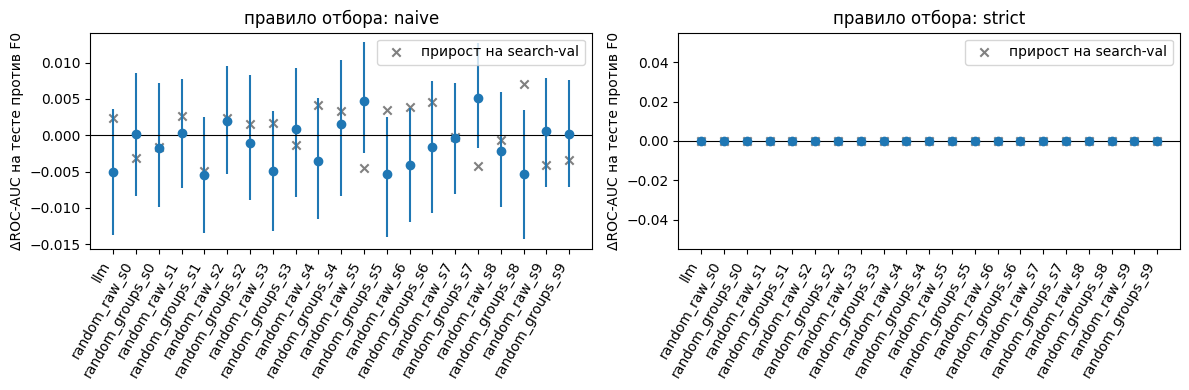

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, rule in enumerate(("naive", "strict")):
    d = summary[summary.rule == rule].reset_index(drop=True)
    ax[i].errorbar(d.index, d.test_delta, yerr=[d.test_delta - d.ci_low, d.ci_high - d.test_delta], fmt="o")
    ax[i].scatter(d.index, d.val_delta, marker="x", color="gray", label="прирост на search-val")
    ax[i].axhline(0, color="k", lw=0.8)
    ax[i].set_xticks(d.index, d.pool, rotation=60, ha="right")
    ax[i].set_title(f"правило отбора: {rule}")
    ax[i].set_ylabel("ΔROC-AUC на тесте против F0")
    ax[i].legend()
plt.tight_layout()

Главная величина здесь share_significant при правиле strict: в какой доле запусков источник нашёл набор признаков,
который дал значимый прирост на тесте. У LLM один запуск, у случайного поиска RANDOM_SEEDS запусков,
поэтому сравнивать надо долю случайных запусков, которые достигли того же, что и LLM.

## 6. Какие признаки отобраны

In [14]:
for name in ("llm",):
    t = results[name]["table"].sort_values("delta", ascending=False).head(10)
    t = t.assign(spec=t["spec"].map(describe))
    display(t[["feature", "delta", "ci_low", "ci_high", "p_value", "spec"]].round(4))

# что отобрали случайные пулы при строгом правиле
for name, r in results.items():
    chosen = r["strict"]["chosen"]
    if name != "llm" and chosen:
        t = r["table"].set_index("feature").loc[chosen]
        print(name, [describe(sp) for sp in t["spec"]])

,feature,delta,ci_low,ci_high,p_value,spec
6,llm_6_7b49603d45,0.0041,-0.0029,0.0124,0.156,"count | 90 дн. | mcc_group=groceries, доля от ..."
33,llm_33_12a1932e89,0.0040,-0.0037,0.0118,0.160,count | вся история | mcc_group=government
37,llm_37_d01e74dded,0.0039,-0.0036,0.0105,0.156,count | 90 дн. | trx_category=['WD_ATM_PARTNER...
28,llm_28_55c6f4ffed,0.0022,-0.0052,0.0099,0.306,"sum(amount) | вся история | mcc_group=travel, ..."
12,llm_12_d928a997f4,0.0022,-0.0047,0.0092,0.258,"count | 90 дн. | trx_category=['C2C_OUT'], дол..."
13,llm_13_e25975ae00,0.0021,-0.0047,0.0093,0.274,sum(amount) | 30 дн. | trx_category=['C2C_OUT'...
35,llm_35_2d2b493e50,0.0018,-0.0060,0.0094,0.308,"count | 30 дн. | mcc_group=entertainment, к ок..."
24,llm_24_d3e5275594,0.0015,-0.0057,0.0084,0.366,max(log_amount) | 30 дн. | все транзакции
17,llm_17_76abc6e43f,0.0012,-0.0052,0.0089,0.396,"count | 90 дн. | mcc_group=telecom_utilities, ..."
14,llm_14_258bd0d0f2,0.0011,-0.0068,0.0090,0.402,days_since_last | вся история | trx_category=[...


## 7. Первый запуск (F0 basic, 3 сида)

В первом запуске F0 был базовым (15 агрегатов без разбивки по категориям), а случайный пул с группами MCC
не имел фильтров по типу операции. Результаты на тесте, прирост ROC-AUC к F0 = 0.702:

- llm, strict: 2 признака, +0.037 [+0.017; +0.058]. Оба про пополнения карты (давность последнего DEPOSIT и тренд суммы пополнений).
- random_raw, strict: значимый признак нашёлся в 1 запуске из 3, там прирост +0.062 [+0.043; +0.080].
- random_groups, strict: 0 из 3, но этому пулу не были доступны фильтры по типу операции, где и сидел сигнал.
- При правиле naive разброс между сидами огромный: у random_raw от +0.002 до +0.079.

Отсюда два исправления, которые сделаны в этой версии. Пул random_groups получил те же фильтры по типам операций,
что и random_raw, иначе сравнение нечестное. F0 по умолчанию сильный: в нём уже есть доли операций по типам и частым MCC.
Если прирост LLM держался только на том, что слабый F0 не видел пополнений, со сильным F0 он должен исчезнуть.

## 8. Как читать результат

- **llm примерно равен random_groups.** Выбор кандидатов LLM ничего не добавляет к группам, вся польза от знания о категориях.
  Тогда LLM достаточно вызвать один раз для группировки MCC, а дальше работает дешёвый перебор.
- **random_groups примерно равен random_raw.** Знание о смысле категорий на этих данных не помогает.
- **llm заметно выше обоих**, и интервалы на тесте не пересекают ноль. Только в этом случае можно говорить о вкладе LLM.
- **Большой overfit_gap у правила naive** значит, что мягкий отбор принимает шум. Поэтому
  сравнивать методы надо с одинаковым и строгим отбором.

Ограничения. Здесь один датасет и одно разбиение, LLM вызвана один раз без обратной связи,
бюджет уравнен по числу кандидатов, а не по времени. В Rosbank метки оттока есть примерно у 5 тыс. клиентов,
интервалы широкие, поэтому отсутствие значимой разницы здесь не доказывает, что её нет вообще.
Для ориентира, в статье EAFD на Rosbank CoLES даёт ROC-AUC 0.835, Featuretools поверх CoLES 0.863, CAAFE 0.870, EAFD 0.872.